# DADA2-working

## 10.6.2026 | dada2-env and ASV table

### Setting up R/DADA2 with conda environment in unity

Create environment `dada2-env` in terminal, much easier than doing it in R! 
```
conda create -n dada2-env python=3.14 
conda activate dada2-env
conda install -c conda-forge -c bioconda --strict-channel-priority r-base r-biocmanager bioconductor-dada2
conda install -c conda-forge r-tidyverse 
# install jupyter and add r kernel
pip install jupyter 
conda install -c conda-forge r-irkernel
```

### Create ASV table

Decided to move forward with the fastp + cutadapt samples for now. Ran the following code to check quality plots and assess where to truncate reads:

Loading required package: Rcpp



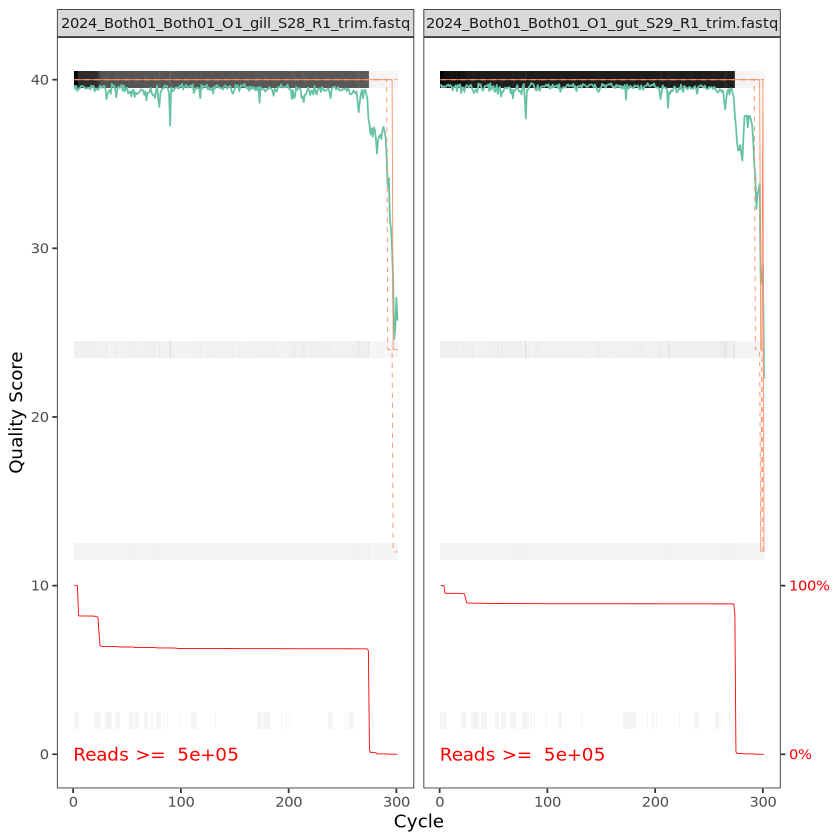

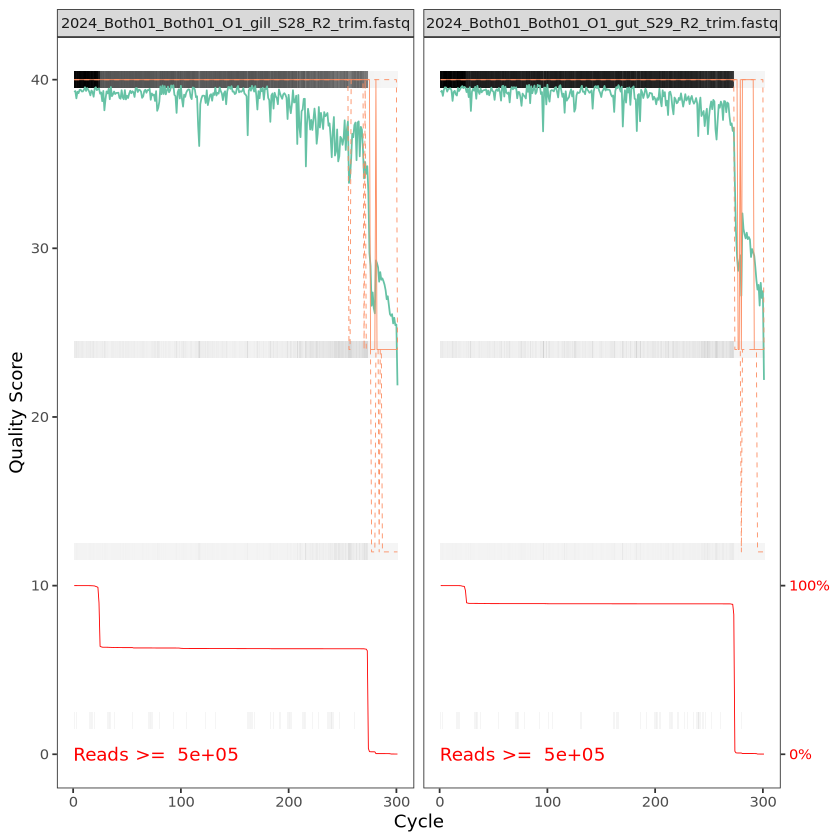

In [3]:
library(dada2)
path <- "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/fastp-cutadapt"
# Forward and reverse fastq filenames
fnFs <- sort(list.files(path, pattern="_R1_trim.fastq", full.names = TRUE))
fnRs <- sort(list.files(path, pattern="_R2_trim.fastq", full.names = TRUE))
# Extract sample names
sample.names <- sub("_S[0-9]+_R[12]_trim\\.fastq$", "", basename(fnFs))
# Check forward reads
plotQualityProfile(fnFs[1:2])
# Check reverse reads
plotQualityProfile(fnRs[1:2])

Truncated forward and reverse read 3' end to 250bp based on the quality plots. Be sure to save ASV tables as an r object (.rds) for downstream applications.   
R script:

In [ ]:
# Load package
library(dada2)

# Set threads to number parametized in slurm
threads <- as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "1"))

# Set path to trimmed fastq files
path <- "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/fastp-cutadapt" 

# Forward and reverse fastq filenames
fnFs <- sort(list.files(path, pattern="_R1_trim.fastq", full.names = TRUE))
fnRs <- sort(list.files(path, pattern="_R2_trim.fastq", full.names = TRUE))

# Extract sample names
sample.names <- sub("_S[0-9]+_R[12]_trim\\.fastq$", "", basename(fnFs))

# Place filtered files in filtered/ subdirectory
filtFs <- file.path(path, "filtered", paste0(sample.names, "_F_filt.fastq.gz"))
filtRs <- file.path(path, "filtered", paste0(sample.names, "_R_filt.fastq.gz"))
names(filtFs) <- sample.names
names(filtRs) <- sample.names

# Filter and truncation
out <- filterAndTrim(fnFs, filtFs, fnRs, filtRs, truncLen=c(250,250),
                    maxN=0, maxEE=c(2,2), truncQ=2, rm.phix=TRUE,
                    compress=TRUE, multithread=threads, verbose=TRUE)
head(out)

# Learn non-random error rates made during sequencing in R1 and R2
errF <- learnErrors(filtFs, multithread=threads)
errR <- learnErrors(filtRs, multithread=threads)
dadaFs <- dada(filtFs, err=errF, multithread=threads)
dadaRs <- dada(filtRs, err=errR, multithread=threads)

# Merge paired reads
mergers <- mergePairs(dadaFs, filtFs, dadaRs, filtRs, verbose=TRUE)

# Make sequence table
seqtab <- makeSequenceTable(mergers)

# Inspect distribution of sequence lengths
dim(seqtab)
table(nchar(getSequences(seqtab)))
saveRDS(seqtab, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASVs.rds")
print("Saved ASV RDS")

# Remove chimeras
seqtab.nochim <- removeBimeraDenovo(seqtab, method="consensus", multithread=threads, verbose=TRUE)
dim(seqtab.nochim)
cat("Percent lost after removing chimeras:", sum(seqtab.nochim)/sum(seqtab))
saveRDS(seqtab.nochim, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim.rds")
print("Saved ASV_nochim RDS")

# Track number of reads
getN <- function(x) sum(getUniques(x))
track <- cbind(out, sapply(dadaFs, getN), sapply(dadaRs, getN), sapply(mergers, getN), rowSums(seqtab.nochim))
colnames(track) <- c("input", "filtered", "denoisedF", "denoisedR", "merged", "nonchim")
rownames(track) <- sample.names
head(track)
write.csv(track, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/read_tracker.csv")

Batch script:
```
#!/bin/bash
#SBATCH -p cpu
#SBATCH --nodes=1
#SBATCH --ntasks=1 
#SBATCH --cpus-per-task=8 # allow multiple threads per node
#SBATCH --mem=30G
#SBATCH -t 72:00:00
#SBATCH --job-name=ASV-table
#SBATCH --mail-type=ALL
#SBATCH -o /scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/slurm-%x-%j.out

module load conda/latest
conda activate dada2-env

# Path to R script
rscript="/work/pi_sarah_gignouxwolfsohn_uml_edu/jade/r-scripts/ASV-table.r"

# Run R script
Rscript "$rscript"
```

## 10.13.26

### Review ASV table

1) There were a few samples that had significant drops in number of input reads to filtered reads. I explored some of the raw fastq files and found what I'm calling sequencing artifacts/errors. In one example, after 100bp ~90% of the bases were a G. This resulted in the short reads I had after running fastp and cutadapt. In the future I can add a minimum length argument `-m 20` to cutadapt to weed these artifacts out earlier.   

![](Images/10.13.26_rawfastqc.png)

2) The removal of chimeras resulted in losing ~10% of the reads, which may be a little high?

3) When playing around with the dada2 quality plots I found that some samples would fail to compile. Decided not to die on this hill right now...


## 10.16.2026 | SILVA taxonomic assignment

### Download fasta training files

Used `wget` to download files directly into my work folder. The toGenus_trainset.fa.gz file pairs with the `assignTaxonomy` function and the assignSpecies.fa.gz file pairs with the `addSpecies` function. I am also interested in playing around with the toSpecies_trainset.fa.gz file which should work with the dada2 function `assignSpecies`. Alternatively, there is another taxonomic assignment tool that I want to explore more! That one requires the .RData file which pairs with the decipher function `IdTaxa`.

### assignTaxonomy using dada2 and SILVA_nr99_v138.2

R script:

In [ ]:
# Load package
library(dada2)

# Set threads to number parametized in slurm
threads <- as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "1"))

# Load csv
seqtab.nochim <- read.csv("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim.csv",
                          row.names = 1, check.names = FALSE)
seqtab.nochim <- as.matrix(seqtab.nochim)
storage.mode(seqtab.nochim) <- "numeric"

# -- AI, turn CSV into format required by dada2
# -- Save as an RDS object next time rather than a csv and use lines below

# Load RDS from ASV-table.r
# seqtab.nochim <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim.rds")

# Assign taxa to genus
taxa <- assignTaxonomy(seqtab.nochim, "/work/pi_sarah_gignouxwolfsohn_uml_edu/jade/silva_nr99_v138.2_toGenus_trainset.fa.gz", 
                       multithread=threads)
saveRDS(taxa, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/taxa_genus.rds")
print("Saved genus RDS")

# Check table
taxa.print <- taxa # Removing sequence rownames for display only
rownames(taxa.print) <- NULL
head(taxa.print)

# Add species information to genus table where possible
taxa <- addSpecies(taxa, "/work/pi_sarah_gignouxwolfsohn_uml_edu/jade/silva_v138.2_assignSpecies.fa.gz")
saveRDS(taxa, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/taxa_species.rds")
print("Saved species RDS")

# Bonus, save csv version
write.csv(taxa, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/taxa_species.csv", quote = FALSE)
print("Saved species csv")

Batch script:
```
#!/bin/bash
#SBATCH -p cpu
#SBATCH --nodes=1
#SBATCH --ntasks=1 
#SBATCH --cpus-per-task=8 # allow multiple threads per node
#SBATCH --mem=30G 
#SBATCH -t 72:00:00 
#SBATCH --job-name=assign-taxonomy
#SBATCH --mail-type=ALL
#SBATCH -o /scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/slurm-%x-%j.out 

module load conda/latest
conda activate dada2-env

# Path to R script
rscript="/work/pi_sarah_gignouxwolfsohn_uml_edu/jade/assign-taxonomy.r"

# Run R script
Rscript "$rscript"
```

### IdTaxa using decipher and SILVA_SSU_r138.2

R-script:

In [ ]:
# Load packages
library(dada2)
library(DECIPHER)

# Load csv
seqtab.nochim <- read.csv("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim.csv", 
                          row.names = 1, check.names = FALSE)
seqtab.nochim <- as.matrix(seqtab.nochim)
storage.mode(seqtab.nochim) <- "numeric"

#  -- AI, turn CSV into format required by dada2
# -- Save as an RDS object next time rather than a csv and use lines below

# Load RDS from ASV-table.r
# seqtab.nochim <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim.rds")

# Create a DNAStringSet from the ASVs
dna <- DNAStringSet(getSequences(seqtab.nochim)) 

# Load training set
load("/work/pi_sarah_gignouxwolfsohn_uml_edu/jade/SILVA_SSU_r138.2_v2.RData") 

# Use all processors
ids <- IdTaxa(dna, trainingSet, strand="top", processors=NULL, verbose=FALSE) 

# Ranks of interest
ranks <- c("domain", "phylum", "class", "order", "family", "genus", "species") 

# Convert the output object of class "Taxa" to a matrix analogous to the output from assignTaxonomy
taxid <- t(sapply(ids, function(x) {
        m <- match(ranks, x$rank)
        taxa <- x$taxon[m]
        taxa[startsWith(taxa, "unclassified_")] <- NA
        taxa
}))
colnames(taxid) <- ranks; rownames(taxid) <- getSequences(seqtab.nochim)

# Check taxa table
taxa.print <- taxid # Removing sequence rownames for display only
rownames(taxa.print) <- NULL
head(taxa.print)

# Save taxa table
saveRDS(taxid, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/decipher_taxa_sp.rds")
print("Saved species RDS")

# Bonus, save csv version
write.csv(taxid, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/decipher_taxa_sp.csv", quote = FALSE)
print("Saved species csv")

Batch script:
```
#!/bin/bash
#SBATCH -p cpu
#SBATCH --nodes=1
#SBATCH --ntasks=1 
#SBATCH --cpus-per-task=8 # allow multiple threads per node
#SBATCH --mem=30G 
#SBATCH -t 72:00:00 
#SBATCH --job-name=decipher-taxonomy
#SBATCH --mail-type=ALL
#SBATCH -o /scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/slurm-%x-%j.out 

module load conda/latest
conda activate dada2-env

# Path to R script
rscript="/work/pi_sarah_gignouxwolfsohn_uml_edu/jade/r-scripts/decipher-taxonomy.r"

# Run R script
Rscript "$rscript"
```

### Check Zymo positive control communities

Going to attempt at a later date when I don't have a time crunch to bust out some figures

In [ ]:
# Load package
library(dada2)

# Compare taxa to the Zymo mock community positive control
unqs.mock <- seqtab.nochim["Positive_control_NA",]
unqs.mock <- sort(unqs.mock[unqs.mock>0], decreasing=TRUE) # Drop ASVs absent in the Mock
cat("DADA2 inferred", length(unqs.mock), "sample sequences present in the Mock community.\n")

# -- AI, combine reference fasta files
ref_dir <- "/work/pi_sarah_gignouxwolfsohn_uml_edu/jade/ZymoBIOMICS.STD.refseq.v2/Genomes"
fasta_files <- list.files(
  ref_dir,
  pattern = "\\.(fasta|fa|fna|fas)$",
  full.names = TRUE,
  recursive = TRUE,
  ignore.case = TRUE
)
mock.ref <- unlist(lapply(fasta_files, getSequences), use.names = FALSE)

# Count ASVs that exactly match at least one reference sequence
match.ref <- sapply(names(unqs.mock), function(x) {
  any(x == mock.ref)
})
cat("Of those,", sum(match.ref), "were exact matches to the expected reference sequences.\n")